# Notebook 06 — LSTM Direction Classifier: Horizon 2008-2024

## Konteks & Tujuan

Notebook `03_LSTM_experiment.ipynb` (metodologi **v5**: enrichment indikator teknikal +
ensemble LSTM anti-overfit + walk-forward rolling + kalibrasi) sebelumnya dilatih pada
rentang **2018-2024** (~6 tahun, 1.552 baris) dan menemukan sinyal yang lemah/mendekati
Efficient Market Hypothesis (mean AUC walk-forward ~0.57, tapi **pooled AUC** ~0.49-0.55 —
edge out-of-sample konsisten hampir tidak ada), dengan gejala **regime-dependent sign-flip**
(pola berbalik arah antar periode market).

Notebook ini menguji apakah memperpanjang horizon waktu ke **2008-2024** (16 tahun,
~4.071 baris) — mencakup **Krisis Finansial Global 2008** dan **Crash COVID-19 2020** —
menghasilkan estimasi sinyal yang lebih *robust* (lebih banyak fold walk-forward, lebih
banyak rezim pasar teruji), memakai **metodologi yang PERSIS SAMA** dengan notebook 03
(v5): 10 fitur (8 indikator teknikal stasioner + 2 sentimen), `LSTMClassifier` anti-overfit
(hidden=32, 1 layer, dropout=0.5, mean-pooling), seed-ensemble 5 model, grid search,
walk-forward rolling + kalibrasi Platt + threshold Youden's J.

**PENTING — ekspektasi yang jujur (bukan janji hasil "sangat bagus"):** memperpanjang
rentang data menambah **keandalan statistik** estimasi (lebih banyak observasi, lebih
banyak fold, mencakup rezim ekstrem) — ini **BUKAN** jaminan sinyal jadi lebih mudah
diprediksi. Prediksi arah harga saham harian/jangka-pendek secara konsisten memang sangat
sulit dikalahkan (mendekati EMH) — ini sudah berulang kali ditemukan di notebook-notebook
sebelumnya. Semua hasil di notebook ini **akan dilaporkan apa adanya**, termasuk bila
hasilnya sama lemahnya (atau lebih lemah) dari 2018-2024 — bukan di-tuning demi angka yang
terlihat bagus (anti p-hacking, prinsip yang sudah disepakati sejak notebook 03 v5).

### Perbedaan dari notebook 03

| Aspek | notebook 03 (v5) | notebook 06 (ini) |
|---|---|---|
| Rentang data | 2018-2024 (~6 tahun, 1.552 baris) | 2008-2024 (~16 tahun, ~4.071 baris) |
| Mencakup krisis | Hanya COVID 2020 | GFC 2008 **dan** COVID 2020 |
| Fitur | 10 fitur | 10 fitur (**sama persis** — tidak menambah indikator baru, apples-to-apples) |
| Arsitektur model | `LSTMClassifier` | `LSTMClassifier` (**sama persis**) |
| Grid search | Dijalankan pada 2018-2024 | **Dijalankan ulang** pada 2008-2024 (hyperparameter optimal bisa beda) |
| Walk-forward folds | 5 fold | **8 fold** (data lebih panjang -> fold lebih granular, menguji regime sign-flip lebih detail) |
| Sensitivity sweep `WF_TRAIN_SIZE` | [200,300,400,500,expanding] | **[200,300,400,500,750,1000,expanding]** |
| Artefak | `*_v5.*` | `*_v6_2008_2024.*` (terisolasi, tidak menimpa v5) |

**Catatan tentang korelasi sentimen:** notebook 03 mengutip temuan korelasi sentimen-vs-return
dari analisis pada rentang 2018-2024 (`sentiment_mean` vs return 5-hari: r=0.275; MA3:
r=0.363). Notebook ini **tidak mengasumsikan** angka korelasi yang sama berlaku persis untuk
rentang 2008-2024 yang jauh lebih panjang — Bagian 0 di bawah melakukan overview data dasar
(bukan analisis korelasi penuh) untuk rentang baru ini sebagai sanity-check, sebelum masuk
ke pipeline v5 yang sama.


In [1]:
# Cell — Import library dan pengaturan seed
import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')

# Tambahkan root project ke sys.path agar pipeline bisa di-import
sys.path.insert(0, os.path.abspath('..'))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
)
from sklearn.preprocessing import StandardScaler

# Modul indikator teknikal & preprocessing dari pipeline project (REUSE, tidak ditulis ulang)
from pipeline.feature_engineering.technical_indicators import compute_technical_indicators
from pipeline.preprocessing.stock_preprocessor import StockPreprocessor

# Seed untuk reproducibility
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device  : {DEVICE}')
print(f'PyTorch : {torch.__version__}')


Device  : cuda
PyTorch : 2.6.0+cu124


## 0. Overview Data 2008-2024 (Sanity Check)

Sanity-check sebelum masuk pipeline v5 — penting karena rentang ini mencakup 2 krisis besar
(Krisis Finansial Global 2008 dan Crash COVID-19 2020), yang berpotensi memunculkan outlier
volatilitas ekstrem atau gap data yang perlu diketahui lebih dulu.


In [2]:
# 0.1 — Load raw OHLCV 2008-2024 (overview sebelum cleaning/pipeline)
RAW_STOCK_PATH_2008 = '../data/raw/stocks/GSPC_2008_2024.csv'

df_raw_overview = pd.read_csv(RAW_STOCK_PATH_2008, parse_dates=['Date'])
df_raw_overview = df_raw_overview.sort_values('Date').reset_index(drop=True)

print('Shape         :', df_raw_overview.shape)
print('Date Range    :', df_raw_overview['Date'].min().date(), '->', df_raw_overview['Date'].max().date())
print('Columns       :', df_raw_overview.columns.tolist())
print()
print('Missing values per kolom:')
print(df_raw_overview.isnull().sum())
df_raw_overview.describe()


Shape         : (4070, 8)
Date Range    : 2008-01-02 -> 2024-03-04
Columns       : ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'Dividends', 'Stock Splits']

Missing values per kolom:
Date            0
Open            0
High            0
Low             0
Close           0
Volume          0
Dividends       0
Stock Splits    0
dtype: int64


,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
count,4070,4070.000000,4070.000000,4070.000000,4070.000000,4.070000e+03,4070.0,4070.0
mean,2016-01-30 20:36:54.840294,2379.750505,2393.381652,2365.160533,2380.239326,4.110010e+09,0.0,0.0
min,2008-01-02 00:00:00,679.280029,695.270020,666.789978,676.530029,0.000000e+00,0.0,0.0
25%,2012-01-14 00:00:00,1357.642517,1365.037537,1347.420044,1357.982483,3.418438e+09,0.0,0.0
50%,2016-02-01 12:00:00,2091.500000,2100.664917,2082.724976,2091.560059,3.872715e+09,0.0,0.0
75%,2020-02-17 00:00:00,3074.625061,3088.397461,3034.702515,3076.240051,4.538980e+09,0.0,0.0
max,2024-03-04 00:00:00,5130.990234,5149.669922,5127.180176,5137.080078,1.145623e+10,0.0,0.0
std,NaN,1137.320244,1142.935466,1131.678765,1137.710048,1.121842e+09,0.0,0.0


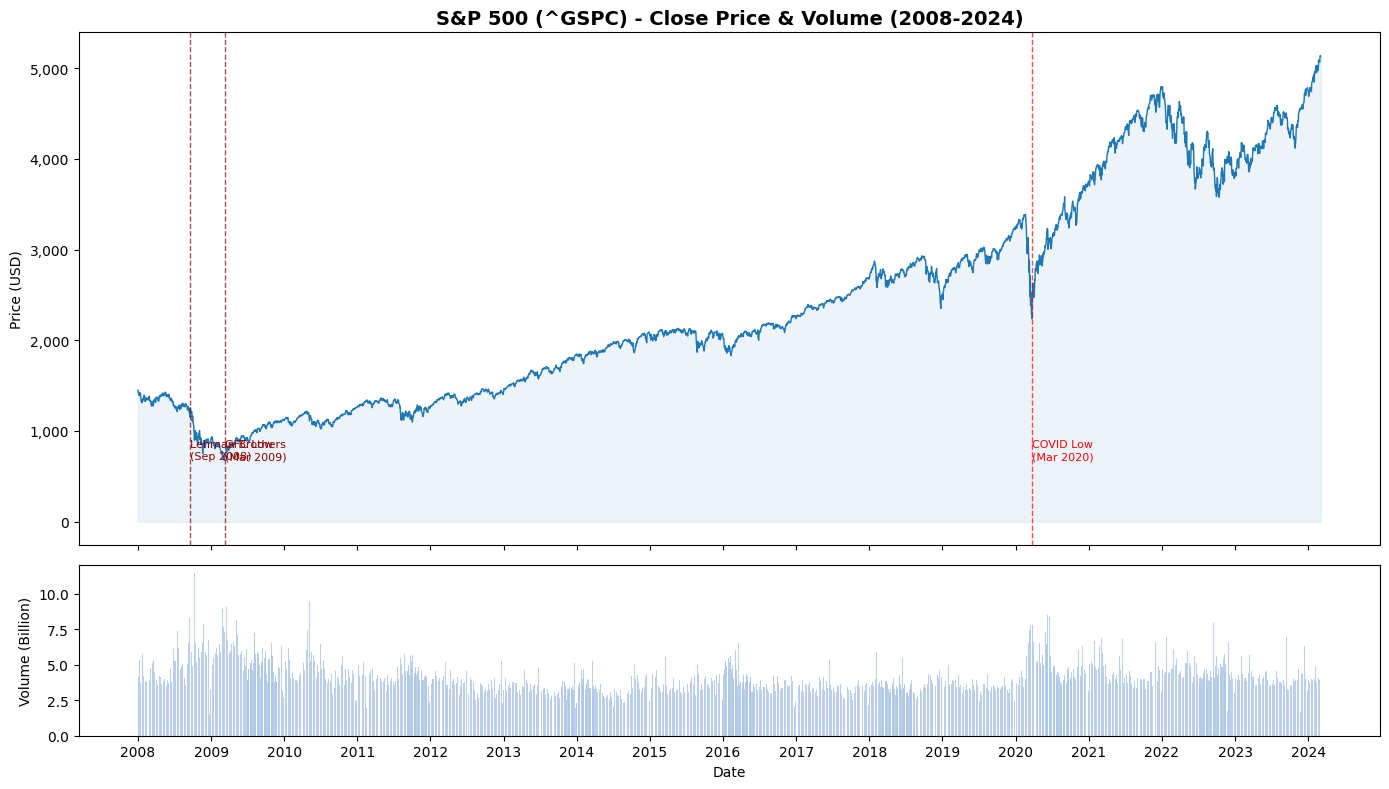

Plot disimpan ke: ../data/artifacts/eda_close_volume_2008_2024.png


In [3]:
# 0.2 — Harga Close + Volume sepanjang 2008-2024, dengan penanda GFC 2008 & COVID 2020
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                                gridspec_kw={'height_ratios': [3, 1]})

ax1.plot(df_raw_overview['Date'], df_raw_overview['Close'], color='#1f77b4', linewidth=1.0)
ax1.fill_between(df_raw_overview['Date'], df_raw_overview['Close'], alpha=0.08, color='#1f77b4')
ax1.set_title('S&P 500 (^GSPC) - Close Price & Volume (2008-2024)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Price (USD)')
ax1.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x:,.0f}'))

# Penanda rezim krisis
for event_date, label, color in [
    (pd.Timestamp('2008-09-15'), 'Lehman Brothers\n(Sep 2008)', 'darkred'),
    (pd.Timestamp('2009-03-09'), 'GFC Low\n(Mar 2009)', 'darkred'),
    (pd.Timestamp('2020-03-23'), 'COVID Low\n(Mar 2020)', 'red'),
]:
    ax1.axvline(event_date, color=color, linestyle='--', alpha=0.7, linewidth=1)
    ax1.text(event_date, df_raw_overview['Close'].min() * 1.02, label, color=color, fontsize=8)

ax2.bar(df_raw_overview['Date'], df_raw_overview['Volume'] / 1e9, color='#aec7e8', width=1.2, alpha=0.85)
ax2.set_ylabel('Volume (Billion)')
ax2.set_xlabel('Date')
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax2.xaxis.set_major_locator(mdates.YearLocator())

plt.tight_layout()
os.makedirs('../data/artifacts', exist_ok=True)
plt.savefig('../data/artifacts/eda_close_volume_2008_2024.png', bbox_inches='tight')
plt.show()
print('Plot disimpan ke: ../data/artifacts/eda_close_volume_2008_2024.png')


In [4]:
# 0.3 — Cek gap tanggal & coverage sentimen sepanjang 2008-2024
date_diffs = df_raw_overview['Date'].diff().dt.days
gap_over_5 = date_diffs[date_diffs > 5]
print(f'Jumlah gap tanggal > 5 hari kalender: {len(gap_over_5)}')
if len(gap_over_5):
    print('Gap terbesar (top 5):')
    print(date_diffs.sort_values(ascending=False).head(5))

SENTIMENT_PATH_OVERVIEW = '../data/processed/sentiment/headlines_daily_sentiment.csv'
df_sent_overview = pd.read_csv(SENTIMENT_PATH_OVERVIEW, parse_dates=['Date'])
print()
print('Sentimen - shape:', df_sent_overview.shape)
print('Sentimen - rentang tanggal:', df_sent_overview['Date'].min().date(), '->', df_sent_overview['Date'].max().date())

merged_check = df_raw_overview[['Date']].merge(df_sent_overview[['Date', 'headline_count']], on='Date', how='left')
low_cov = (merged_check['headline_count'].fillna(0) <= 2).sum()
no_cov  = merged_check['headline_count'].isnull().sum()
print(f'Hari OHLCV tanpa data sentimen sama sekali : {no_cov} dari {len(merged_check)}')
print(f'Hari dengan headline_count <= 2 (coverage rendah): {low_cov} dari {len(merged_check)}')


Jumlah gap tanggal > 5 hari kalender: 0

Sentimen - shape: (3504, 7)
Sentimen - rentang tanggal: 2008-01-02 -> 2024-03-04
Hari OHLCV tanpa data sentimen sama sekali : 566 dari 4070
Hari dengan headline_count <= 2 (coverage rendah): 1720 dari 4070


## 1. Load, Bersihkan, & Merge Data

Langkah-langkah:
1. Load OHLCV harian S&P500 2008-2024 (`GSPC_2008_2024.csv`), bersihkan via
   `StockPreprocessor.clean()` (reuse dari `pipeline/preprocessing/`, tidak ditulis ulang),
   simpan hasil ke `data/processed/stocks/GSPC_2008_2024.csv`.
2. Load sentimen harian hasil FinBERT (`headlines_daily_sentiment.csv`, sudah mencakup 2008-2024).
3. Left-merge sentimen ke OHLCV berdasarkan tanggal.
4. **Penanganan coverage rendah**: hari dengan `headline_count <= 2` -> netralkan ke 0.
5. **Perataan**: hitung rolling-MA3 sentimen.
6. **Anti look-ahead**: geser sentimen 1 hari ke belakang (pakai sentimen kemarin).


In [5]:
# 1.1 — Bersihkan raw OHLCV 2008-2024 via StockPreprocessor (REUSE, tidak ditulis ulang)
RAW_STOCK_PATH       = '../data/raw/stocks/GSPC_2008_2024.csv'
PROCESSED_STOCK_PATH = '../data/processed/stocks/GSPC_2008_2024.csv'

_preprocessor = StockPreprocessor()
_df_raw = _preprocessor.load_csv(RAW_STOCK_PATH)
df_price_clean = _preprocessor.clean(_df_raw)

os.makedirs(os.path.dirname(PROCESSED_STOCK_PATH), exist_ok=True)
df_price_clean.to_csv(PROCESSED_STOCK_PATH, index=False)
print(f'Data bersih disimpan ke: {PROCESSED_STOCK_PATH}')
print(f'Shape setelah cleaning : {df_price_clean.shape}')
print(f'Rentang tanggal        : {df_price_clean["Date"].min().date()} -- {df_price_clean["Date"].max().date()}')


Data bersih disimpan ke: ../data/processed/stocks/GSPC_2008_2024.csv
Shape setelah cleaning : (4070, 6)
Rentang tanggal        : 2008-01-02 -- 2024-03-04


In [6]:
# 1.2 — Load data (dari processed), merge, rekayasa fitur sentimen

OHLCV_PATH     = '../data/processed/stocks/GSPC_2008_2024.csv'
SENTIMENT_PATH = '../data/processed/sentiment/headlines_daily_sentiment.csv'

# --- 1. Load OHLCV (sudah bersih dari 1.1) ---
df_price = pd.read_csv(OHLCV_PATH, parse_dates=['Date'])
df_price = df_price.sort_values('Date').reset_index(drop=True)
df_price = df_price.drop(columns=['Dividends', 'Stock Splits'], errors='ignore')

# --- 2. Load sentimen ---
df_sent = pd.read_csv(SENTIMENT_PATH, parse_dates=['Date'])
df_sent = df_sent[['Date', 'sentiment_mean', 'sentiment_neg', 'headline_count']].copy()

# --- 3. Merge (left join agar semua hari OHLCV tetap ada) ---
df = df_price.merge(df_sent, on='Date', how='left')

# --- 4. Penanganan coverage rendah ---
low_coverage_mask = df['headline_count'].fillna(0) <= 2
df.loc[low_coverage_mask, 'sentiment_mean'] = 0.0
df.loc[low_coverage_mask, 'sentiment_neg']  = 0.0
print(f'Hari dengan coverage rendah (headline_count <= 2): {low_coverage_mask.sum()}')

df['sentiment_mean'] = df['sentiment_mean'].fillna(0.0)
df['sentiment_neg']  = df['sentiment_neg'].fillna(0.0)

# --- 5. Rolling-MA3 sentimen ---
df['sentiment_mean_ma3'] = df['sentiment_mean'].rolling(3, min_periods=1).mean()

# --- 6. Anti look-ahead: geser semua sentimen 1 hari ---
df['sentiment_mean']     = df['sentiment_mean'].shift(1)
df['sentiment_neg']      = df['sentiment_neg'].shift(1)
df['sentiment_mean_ma3'] = df['sentiment_mean_ma3'].shift(1)

print(f'Shape setelah merge: {df.shape}')
print(f'Kolom: {df.columns.tolist()}')
print(f'Rentang tanggal: {df["Date"].min().date()} -- {df["Date"].max().date()}')
df.head()


Hari dengan coverage rendah (headline_count <= 2): 1720
Shape setelah merge: (4070, 10)
Kolom: ['Date', 'Open', 'High', 'Low', 'Close', 'Volume', 'sentiment_mean', 'sentiment_neg', 'headline_count', 'sentiment_mean_ma3']
Rentang tanggal: 2008-01-02 -- 2024-03-04


,Date,Open,High,Low,Close,Volume,sentiment_mean,sentiment_neg,headline_count,sentiment_mean_ma3
0,2008-01-02,1467.969971,1471.770020,1442.069946,1447.160034,3452650000,NaN,NaN,3.0,NaN
1,2008-01-03,1447.550049,1456.800049,1443.729980,1447.160034,3429500000,-0.522108,0.666667,1.0,-0.522108
2,2008-01-04,1444.010010,1444.010010,1411.189941,1411.630005,4166000000,0.000000,0.000000,NaN,-0.261054
3,2008-01-07,1414.069946,1423.869995,1403.449951,1416.180054,4221260000,0.000000,0.000000,1.0,-0.174036
4,2008-01-08,1415.709961,1430.280029,1388.300049,1390.189941,4705390000,0.000000,0.000000,NaN,0.000000


In [7]:
# 1.3 — Hitung indikator teknikal, transform stasioner, bersihkan kolom
#
# URUTAN WAJIB:
#   a) Hitung indikator teknikal DARI kolom OHLCV level (sebelum di-drop)
#   b) Buat Close_raw (untuk target di 1.4)
#   c) Bangun fitur stasioner turunan indikator
#   d) Buat ret_close & ret_volume (pct_change)
#   e) Drop kolom level & indikator level yang tidak dipakai sebagai fitur
#   f) Buang baris NaN warmup indikator
#
# Catatan: indikator turunan harga (close_vs_ema20, bb_pct_b, dll.) dinyatakan
# dalam bentuk stasioner (rasio/selisih terhadap moving average) - bukan level
# harga mentah. Semua operasi bersifat causal (rolling/ewm ke belakang, tidak
# ada look-ahead).

# --- a) Hitung indikator teknikal dari OHLCV level ---
df = compute_technical_indicators(df)
# Kolom baru yang dihasilkan:
# ema_20, ema_50, rsi_14, macd, macd_signal, macd_hist,
# bb_mid, bb_upper, bb_lower, bb_bandwidth, daily_return, volatility_20

# --- b) Simpan Close asli untuk membangun target di 1.4 ---
df['Close_raw'] = df['Close'].copy()

# --- c) Fitur stasioner turunan indikator ---
df['close_vs_ema20'] = df['Close'] / df['ema_20'] - 1
df['bb_pct_b'] = (df['Close'] - df['bb_lower']) / (df['bb_upper'] - df['bb_lower'])
# rsi_14, macd_hist, bb_bandwidth, volatility_20 sudah stasioner - pakai langsung

# --- d) Return persentase untuk Close dan Volume ---
df['ret_close']  = df['Close'].pct_change()
df['ret_volume'] = df['Volume'].pct_change()

# --- e) Drop kolom level & indikator level yang tidak dipakai sebagai fitur ---
cols_to_drop = [
    'Open', 'High', 'Low', 'Close', 'Volume',
    'ema_20', 'ema_50',
    'macd', 'macd_signal',
    'bb_mid', 'bb_upper', 'bb_lower',
    'daily_return',
    'headline_count',
    'sentiment_neg',
]
df = df.drop(columns=cols_to_drop, errors='ignore')

# --- f) Buang baris NaN dari warmup indikator ---
FEATURE_COLS_PARTIAL = [
    'ret_close', 'ret_volume', 'rsi_14', 'macd_hist',
    'bb_bandwidth', 'volatility_20', 'close_vs_ema20', 'bb_pct_b',
    'sentiment_mean',
]
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=FEATURE_COLS_PARTIAL).reset_index(drop=True)

print(f'Shape setelah enrichment indikator teknikal: {df.shape}')
print(f'Kolom: {df.columns.tolist()}')
df.describe()


Shape setelah enrichment indikator teknikal: (4049, 12)
Kolom: ['Date', 'sentiment_mean', 'sentiment_mean_ma3', 'rsi_14', 'macd_hist', 'bb_bandwidth', 'volatility_20', 'Close_raw', 'close_vs_ema20', 'bb_pct_b', 'ret_close', 'ret_volume']


,Date,sentiment_mean,sentiment_mean_ma3,rsi_14,macd_hist,bb_bandwidth,volatility_20,Close_raw,close_vs_ema20,bb_pct_b,ret_close,ret_volume
count,4049,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000,4049.000000
mean,2016-02-13 16:58:12.417881,-0.035760,-0.035799,54.913978,0.086373,0.066862,0.010528,2384.748651,0.003015,0.591284,0.000410,0.017106
min,2008-01-31 00:00:00,-0.947043,-0.655740,16.457584,-61.221101,0.010495,0.002072,676.530029,-0.186855,-0.466826,-0.119841,-1.000000
25%,2012-02-06 00:00:00,-0.064206,-0.090208,46.735761,-3.407155,0.038495,0.006064,1358.439941,-0.005873,0.345611,-0.004204,-0.077961
50%,2016-02-16 00:00:00,0.000000,0.000000,56.157955,0.210848,0.055294,0.008556,2095.149902,0.007754,0.679509,0.000687,-0.003160
75%,2020-02-24 00:00:00,0.000000,0.000747,63.567445,3.936553,0.078372,0.012471,3085.179932,0.016942,0.850741,0.005988,0.087303
max,2024-03-04 00:00:00,0.653321,0.407922,86.686650,60.895804,0.433531,0.061182,5137.080078,0.077480,1.290744,0.115800,3.234605
std,NaN,0.179366,0.115259,11.353301,9.340771,0.048209,0.007589,1138.130375,0.023353,0.325279,0.012860,0.204390


In [8]:
# 1.4 — Bangun target: arah 5-hari ke depan

HORIZON   = 5     # prediksi 5 hari ke depan (bukan 1 hari)
THRESHOLD = 0.01  # filter zona netral +/-1%

df['fwd_ret'] = df['Close_raw'].pct_change(HORIZON).shift(-HORIZON)

before_filter = len(df)
df = df[df['fwd_ret'].abs() >= THRESHOLD].copy()
after_filter = len(df)

df['target'] = (df['fwd_ret'] > 0).astype(int)

df = df.drop(columns=['Close_raw', 'fwd_ret'])
df = df.dropna().reset_index(drop=True)

print(f'Baris sebelum filter threshold: {before_filter}')
print(f'Baris setelah filter threshold: {after_filter}')
print(f'Baris setelah dropna final    : {len(df)}')
print()
vc = df['target'].value_counts()
print(f'Distribusi target:')
print(f'  Up   (1): {vc.get(1,0)} ({vc.get(1,0)/len(df)*100:.1f}%)')
print(f'  Down (0): {vc.get(0,0)} ({vc.get(0,0)/len(df)*100:.1f}%)')


Baris sebelum filter threshold: 4049
Baris setelah filter threshold: 2377
Baris setelah dropna final    : 2377

Distribusi target:
  Up   (1): 1427 (60.0%)
  Down (0): 950 (40.0%)


## 2. Fitur & Urutan (Sequences)

### 10 Fitur v5 (SAMA PERSIS notebook 03 - apples-to-apples, tidak ditambah indikator baru)

| # | Fitur | Tipe | Alasan Dimasukkan |
|---|---|---|---|
| 1 | `ret_close` | OHLCV (pct_change) | Dinamika harga stasioner - sinyal utama |
| 2 | `ret_volume` | OHLCV (pct_change) | Volume momentum stasioner |
| 3 | `rsi_14` | Indikator teknikal | Oversold/overbought; sudah bounded 0-100 |
| 4 | `macd_hist` | Indikator teknikal | Momentum selisih EMA; stasioner |
| 5 | `bb_bandwidth` | Indikator teknikal | Volatilitas regime; stasioner |
| 6 | `volatility_20` | Indikator teknikal | Volatilitas rolling; stasioner |
| 7 | `close_vs_ema20` | Indikator turunan | Tren jangka pendek (Close/EMA20 - 1); stasioner |
| 8 | `bb_pct_b` | Indikator turunan | Posisi dalam band; stasioner |
| 9 | `sentiment_mean` | Sentimen | FinBERT shifted(1) hari - anti look-ahead |
| 10 | `sentiment_mean_ma3` | Sentimen halus | Rolling-MA3 sentimen shifted(1) |

Total: **10 fitur**, `WINDOW_SIZE` default 20 hari (akan divalidasi ulang via grid search di
Bagian 4, sama seperti notebook 03). Semua fitur dinormalisasi via `StandardScaler` yang
difit hanya pada data train (anti-leakage).


In [9]:
# 2.1 — Definisi fitur, pembangunan urutan, scaling anti-leakage, dan pembagian data

FEATURE_COLS = [
    'ret_close',
    'ret_volume',
    'rsi_14',
    'macd_hist',
    'bb_bandwidth',
    'volatility_20',
    'close_vs_ema20',
    'bb_pct_b',
    'sentiment_mean',
    'sentiment_mean_ma3',
]

WINDOW_SIZE = 20  # panjang urutan look-back default (sebelum divalidasi grid search)


def build_sequences(df, window, feature_cols, target_col='target'):
    """Bangun urutan sliding window (X, y, dates) dari DataFrame.

    Args:
        df          : DataFrame yang sudah bersih & terurut berdasarkan tanggal
        window      : Panjang look-back (jumlah hari per sampel)
        feature_cols: Nama kolom fitur
        target_col  : Nama kolom target

    Returns:
        X     : np.ndarray shape (N, window, n_features)
        y     : np.ndarray shape (N,)
        dates : np.ndarray tanggal prediksi (hari terakhir tiap window)
    """
    X_list, y_list, date_list = [], [], []
    feat = df[feature_cols].values
    tgt  = df[target_col].values
    dates = df['Date'].values

    for i in range(window, len(df)):
        X_list.append(feat[i - window:i])
        y_list.append(tgt[i])
        date_list.append(dates[i])

    return (
        np.array(X_list, dtype=np.float32),
        np.array(y_list, dtype=np.int64),
        np.array(date_list),
    )


def scale_sequences(X_tr, X_vl, X_te):
    """Fit StandardScaler pada data TRAIN saja (anti-leakage), transform semua split.

    Args:
        X_tr : np.ndarray shape (N_train, window, n_features)
        X_vl : np.ndarray shape (N_val,   window, n_features)
        X_te : np.ndarray shape (N_test,  window, n_features)

    Returns:
        X_tr_scaled, X_vl_scaled, X_te_scaled : array yang sudah di-scale
        scaler                                 : StandardScaler yang sudah difit
    """
    n_feat = X_tr.shape[2]
    scaler = StandardScaler().fit(X_tr.reshape(-1, n_feat))

    def _tf(X):
        if len(X) == 0:
            return X
        return scaler.transform(X.reshape(-1, n_feat)).reshape(X.shape).astype(np.float32)

    return _tf(X_tr), _tf(X_vl), _tf(X_te), scaler


X_all, y_all, dates_all = build_sequences(df, WINDOW_SIZE, FEATURE_COLS)
N = len(X_all)

# Pembagian kronologis 70 / 15 / 15
train_end = int(N * 0.70)
val_end   = int(N * 0.85)

X_train, y_train = X_all[:train_end], y_all[:train_end]
X_val,   y_val   = X_all[train_end:val_end], y_all[train_end:val_end]
X_test,  y_test  = X_all[val_end:], y_all[val_end:]

dates_train = dates_all[:train_end]
dates_val   = dates_all[train_end:val_end]
dates_test  = dates_all[val_end:]

X_train, X_val, X_test, feature_scaler = scale_sequences(X_train, X_val, X_test)

print(f'Total sampel    : {N}')
print(f'Train  : {X_train.shape}  [{pd.Timestamp(dates_train[0]).date()} -- {pd.Timestamp(dates_train[-1]).date()}]')
print(f'Val    : {X_val.shape}  [{pd.Timestamp(dates_val[0]).date()} -- {pd.Timestamp(dates_val[-1]).date()}]')
print(f'Test   : {X_test.shape}  [{pd.Timestamp(dates_test[0]).date()} -- {pd.Timestamp(dates_test[-1]).date()}]')
print()
print(f'Up% Train: {y_train.mean()*100:.1f}%  Val: {y_val.mean()*100:.1f}%  Test: {y_test.mean()*100:.1f}%')
print(f'Fitur    : {len(FEATURE_COLS)} - {FEATURE_COLS}')


Total sampel    : 2357
Train  : (1649, 20, 10)  [2008-03-17 -- 2019-10-18]
Val    : (354, 20, 10)  [2019-10-21 -- 2022-01-10]
Test   : (354, 20, 10)  [2022-01-11 -- 2024-02-26]

Up% Train: 59.0%  Val: 68.9%  Test: 57.1%
Fitur    : 10 - ['ret_close', 'ret_volume', 'rsi_14', 'macd_hist', 'bb_bandwidth', 'volatility_20', 'close_vs_ema20', 'bb_pct_b', 'sentiment_mean', 'sentiment_mean_ma3']


In [10]:
# 2.2 — Dataset PyTorch & DataLoader

BATCH_SIZE = 32


class StockDataset(Dataset):
    """Dataset urutan saham untuk klasifikasi arah harga."""

    def __init__(self, X: np.ndarray, y: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


train_loader = DataLoader(StockDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=False)
val_loader   = DataLoader(StockDataset(X_val,   y_val),   batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(StockDataset(X_test,  y_test),  batch_size=BATCH_SIZE, shuffle=False)

print(f'Batch train : {len(train_loader)}')
print(f'Batch val   : {len(val_loader)}')
print(f'Batch test  : {len(test_loader)}')
print()
vc_train = pd.Series(y_train).value_counts().sort_index()
print('Distribusi kelas di train set:')
print(f'  Down (0): {vc_train.get(0,0)}  Up (1): {vc_train.get(1,0)}')


Batch train : 52
Batch val   : 12
Batch test  : 12

Distribusi kelas di train set:
  Down (0): 676  Up (1): 973


## 3. Arsitektur LSTM

Desain menggunakan **mean-pooling** seluruh output time-step (bukan hanya hidden state
terakhir) untuk menangkap informasi dari sepanjang jendela look-back, bukan hanya titik
terakhir. Arsitektur ini **sama persis** dengan notebook 03 (v5) - tidak diubah.

```
Input (batch, window, 10)
  |--> nn.LSTM  -> output (batch, window, hidden)
         |--> .mean(dim=1)          # rata-rata seluruh time-step
              |--> nn.Dropout
                   |--> nn.Linear(hidden, 2)  # logit Down / Up
```


In [11]:
# 3.1 — Definisi arsitektur LSTMClassifier (SAMA PERSIS notebook 03)

class LSTMClassifier(nn.Module):
    """Klasifikasi arah harga dengan LSTM + mean-pooling.

    Args:
        input_size  : Jumlah fitur input (10 untuk v5)
        hidden_size : Ukuran hidden state LSTM (default 32 - kapasitas kecil, anti-overfit)
        num_layers  : Jumlah layer LSTM yang ditumpuk (default 1)
        dropout     : Dropout di FC layer setelah mean-pooling (default 0.5)
        num_classes : Jumlah kelas output (2: Down / Up)
    """

    def __init__(
        self,
        input_size: int,
        hidden_size: int = 32,
        num_layers: int = 1,
        dropout: float = 0.5,
        num_classes: int = 2,
    ):
        super().__init__()
        lstm_dropout = dropout if num_layers > 1 else 0.0
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=lstm_dropout,
        )
        self.dropout = nn.Dropout(dropout)
        self.fc      = nn.Linear(hidden_size, num_classes)

    def forward(self, x):
        out, _ = self.lstm(x)            # (batch, window, hidden_size)
        pooled = out.mean(dim=1)         # mean-pooling -> (batch, hidden_size)
        pooled = self.dropout(pooled)
        logits = self.fc(pooled)         # (batch, num_classes)
        return logits


INPUT_SIZE = len(FEATURE_COLS)  # 10

_demo = LSTMClassifier(input_size=INPUT_SIZE)
n_params = sum(p.numel() for p in _demo.parameters() if p.requires_grad)
print(_demo)
print(f'\nDefault: hidden_size=32, num_layers=1, dropout=0.5')
print(f'Jumlah parameter yang dapat dilatih: {n_params:,}')


LSTMClassifier(
  (lstm): LSTM(10, 32, batch_first=True)
  (dropout): Dropout(p=0.5, inplace=False)
  (fc): Linear(in_features=32, out_features=2, bias=True)
)

Default: hidden_size=32, num_layers=1, dropout=0.5
Jumlah parameter yang dapat dilatih: 5,698


In [12]:
# 3.2 — Fungsi bantu: train_epoch, evaluate, train_one, ensemble_predict
# (SAMA PERSIS notebook 03 - logic training generic, tidak bergantung rentang data)


def train_epoch(model, loader, optimizer, criterion, device):
    """Satu epoch pelatihan. Mengembalikan (loss_rata2, akurasi)."""
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        logits = model(X_batch)
        loss   = criterion(logits, y_batch)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        total_loss += loss.item() * len(y_batch)
        preds       = logits.argmax(dim=1)
        correct    += (preds == y_batch).sum().item()
        total      += len(y_batch)

    return total_loss / total, correct / total


def evaluate(model, loader, criterion, device):
    """Evaluasi model. Mengembalikan (loss, akurasi, auc)."""
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_labels, all_probs = [], []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            logits = model(X_batch)
            loss   = criterion(logits, y_batch)

            total_loss += loss.item() * len(y_batch)
            preds       = logits.argmax(dim=1)
            correct    += (preds == y_batch).sum().item()
            total      += len(y_batch)

            probs = torch.softmax(logits, dim=1)[:, 1]
            all_labels.extend(y_batch.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    avg_loss = total_loss / total
    acc      = correct / total
    try:
        auc = roc_auc_score(all_labels, all_probs)
    except ValueError:
        auc = 0.5

    return avg_loss, acc, auc


def train_one(Xtr, ytr, Xvl, yvl, params, seed, n_epochs=50, patience=7, lr=1e-3):
    """Latih satu model dengan seed tertentu, early stopping by val AUC.

    Memakai:
    - class weight inverse-frequency dari distribusi ytr (anti imbalance)
    - Adam weight_decay=1e-4 (L2 regularisasi)
    - ReduceLROnPlateau (mode='max', patience=3, factor=0.5)

    Returns:
        model    : LSTMClassifier terbaik (best val AUC)
        hist     : dict {'train_auc': [...], 'val_auc': [...]}
        best_auc : float val AUC terbaik
    """
    torch.manual_seed(seed)
    np.random.seed(seed)

    cnt = np.bincount(ytr, minlength=2)
    w = torch.tensor([1.0 / max(cnt[0], 1), 1.0 / max(cnt[1], 1)], dtype=torch.float32)
    w = (w / w.sum() * 2).to(DEVICE)
    crit = nn.CrossEntropyLoss(weight=w)

    model = LSTMClassifier(len(FEATURE_COLS), **params).to(DEVICE)
    opt   = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='max', patience=3, factor=0.5)

    tr_ld = DataLoader(StockDataset(Xtr, ytr), batch_size=32, shuffle=False)
    vl_ld = DataLoader(StockDataset(Xvl, yvl), batch_size=32, shuffle=False)

    best_auc, best_state, no_imp = 0.0, None, 0
    hist = {'train_auc': [], 'val_auc': []}

    for ep in range(1, n_epochs + 1):
        train_epoch(model, tr_ld, opt, crit, DEVICE)
        _, _, tauc = evaluate(model, tr_ld, crit, DEVICE)
        _, _, vauc = evaluate(model, vl_ld, crit, DEVICE)
        hist['train_auc'].append(tauc)
        hist['val_auc'].append(vauc)
        sched.step(vauc)
        if vauc > best_auc:
            best_auc, no_imp = vauc, 0
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            no_imp += 1
        if no_imp >= patience:
            break

    model.load_state_dict({k: v.to(DEVICE) for k, v in best_state.items()})
    return model, hist, best_auc


def ensemble_predict(models, X):
    """Rata-ratakan probabilitas P(Up) dari daftar model (seed ensemble).

    Returns:
        probs_mean : np.ndarray shape (N,) - rata-rata P(Up) dari seluruh model
    """
    dummy_y = np.zeros(len(X), dtype=np.int64)
    ld = DataLoader(StockDataset(X, dummy_y), batch_size=32, shuffle=False)
    probs_sum = None
    for m in models:
        m.eval()
        ps = []
        with torch.no_grad():
            for Xb, _ in ld:
                ps.extend(torch.softmax(m(Xb.to(DEVICE)), 1)[:, 1].cpu().numpy())
        ps = np.array(ps)
        probs_sum = ps if probs_sum is None else probs_sum + ps
    return probs_sum / len(models)


print('Fungsi train_epoch, evaluate, train_one, dan ensemble_predict siap digunakan.')


# =========================================================
# Helper tambahan: threshold tuning, kalibrasi Platt, metrik lengkap
# =========================================================
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.linear_model import LogisticRegression


def tune_threshold(y_val, p_val, metric='youden'):
    """Cari threshold optimal pada VALIDATION (anti-leakage: jangan pakai test).
    metric='youden': maksimalkan Youden's J = TPR - FPR.
    metric='f1'    : maksimalkan F1 (alternatif).
    Grid 0.30..0.70."""
    y_val = np.asarray(y_val); p_val = np.asarray(p_val)
    grid = np.linspace(0.30, 0.70, 41)
    best_t, best_s = 0.5, -1.0
    for t in grid:
        preds = (p_val >= t).astype(int)
        if metric == 'youden':
            tp = int(np.sum((preds == 1) & (y_val == 1)))
            fn = int(np.sum((preds == 0) & (y_val == 1)))
            tn = int(np.sum((preds == 0) & (y_val == 0)))
            fp = int(np.sum((preds == 1) & (y_val == 0)))
            tpr = tp / (tp + fn) if (tp + fn) > 0 else 0.0
            fpr = fp / (fp + tn) if (fp + tn) > 0 else 0.0
            s = tpr - fpr
        else:
            s = f1_score(y_val, preds, zero_division=0)
        if s > best_s:
            best_s, best_t = s, t
    return float(best_t)


def calibrate_platt(p_val, y_val, p_test):
    """Platt scaling: fit LogisticRegression pada (p_val -> y_val), transform p_test.
    Jika val hanya 1 kelas, kembalikan p_test apa adanya."""
    if len(np.unique(y_val)) < 2:
        return p_test
    lr = LogisticRegression().fit(np.asarray(p_val).reshape(-1, 1), np.asarray(y_val))
    return lr.predict_proba(np.asarray(p_test).reshape(-1, 1))[:, 1]


def full_metrics(y, p, thr=0.5):
    """Hitung auc, accuracy, precision, recall, f1 pada threshold thr."""
    y = np.asarray(y); p = np.asarray(p)
    preds = (p >= thr).astype(int)
    auc = roc_auc_score(y, p) if len(np.unique(y)) > 1 else float('nan')
    return {
        'auc': auc,
        'accuracy': accuracy_score(y, preds),
        'precision': precision_score(y, preds, zero_division=0),
        'recall': recall_score(y, preds, zero_division=0),
        'f1': f1_score(y, preds, zero_division=0),
    }


print('Helper tune_threshold, calibrate_platt, full_metrics siap digunakan.')


Fungsi train_epoch, evaluate, train_one, dan ensemble_predict siap digunakan.
Helper tune_threshold, calibrate_platt, full_metrics siap digunakan.


## 4. Pencarian Hyperparameter (Grid Search)

**Dijalankan ulang dari nol** pada dataset 2008-2024 (bukan reuse angka dari notebook 03) -
hyperparameter optimal kemungkinan berbeda karena distribusi data 16 tahun sangat berbeda
dari 6 tahun. Titik awal PARAM_GRID sama seperti notebook 03 (5 konfigurasi, semua
`num_layers=1`, dropout tinggi) sebagai baseline pencarian.

Kriteria terbaik: **val AUC**. Scheduler: `ReduceLROnPlateau(mode='max', patience=3,
factor=0.5)`. Early stopping: `patience=7` epoch tanpa perbaikan val AUC.


In [13]:
# 4.1 — Grid search hyperparameter (kapasitas kecil, anti-overfit)

PARAM_GRID = [
    {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 1e-3,  'window': 20},
    {'hidden_size': 16, 'num_layers': 1, 'dropout': 0.5, 'lr': 1e-3,  'window': 20},
    {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 5e-4,  'window': 30},
    {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.4, 'lr': 1e-3,  'window': 10},
    {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.5, 'lr': 5e-4,  'window': 20},
]

N_EPOCHS = 50
PATIENCE = 7

results      = []
best_val_auc = -1.0
best_params  = None
best_window  = WINDOW_SIZE
best_lr      = 1e-3

for cfg_idx, cfg in enumerate(PARAM_GRID):
    window = cfg['window']

    X_all_w, y_all_w, _ = build_sequences(df, window, FEATURE_COLS)
    N_w  = len(X_all_w)
    te_w = int(N_w * 0.70)
    ve_w = int(N_w * 0.85)

    Xtr_w, ytr_w = X_all_w[:te_w],      y_all_w[:te_w]
    Xvl_w, yvl_w = X_all_w[te_w:ve_w],  y_all_w[te_w:ve_w]
    Xte_w, yte_w = X_all_w[ve_w:],      y_all_w[ve_w:]

    Xtr_s, Xvl_s, _, _ = scale_sequences(Xtr_w, Xvl_w, Xte_w)

    cnt = np.bincount(ytr_w, minlength=2)
    w = torch.tensor([1.0 / max(cnt[0], 1), 1.0 / max(cnt[1], 1)], dtype=torch.float32)
    w = (w / w.sum() * 2).to(DEVICE)
    criterion_gs = nn.CrossEntropyLoss(weight=w)

    tr_loader_gs = DataLoader(StockDataset(Xtr_s, ytr_w), batch_size=BATCH_SIZE, shuffle=False)
    vl_loader_gs = DataLoader(StockDataset(Xvl_s, yvl_w), batch_size=BATCH_SIZE, shuffle=False)

    model_cfg = {k: v for k, v in cfg.items() if k not in ('lr', 'window')}
    model_gs  = LSTMClassifier(input_size=INPUT_SIZE, **model_cfg).to(DEVICE)
    opt_gs    = torch.optim.Adam(model_gs.parameters(), lr=cfg['lr'], weight_decay=1e-4)
    sched_gs  = torch.optim.lr_scheduler.ReduceLROnPlateau(
        opt_gs, mode='max', patience=3, factor=0.5
    )

    best_auc_run   = -1.0
    best_state_run = None
    no_improve     = 0

    print(f'\n[Konfigurasi {cfg_idx+1}/{len(PARAM_GRID)}] {cfg}')

    for epoch in range(1, N_EPOCHS + 1):
        train_epoch(model_gs, tr_loader_gs, opt_gs, criterion_gs, DEVICE)
        _, _, vl_auc = evaluate(model_gs, vl_loader_gs, criterion_gs, DEVICE)
        sched_gs.step(vl_auc)

        if vl_auc > best_auc_run:
            best_auc_run   = vl_auc
            best_state_run = {k: v.cpu().clone() for k, v in model_gs.state_dict().items()}
            no_improve     = 0
        else:
            no_improve += 1

        if epoch % 10 == 0:
            print(f'  Epoch {epoch:3d} | vl_auc={vl_auc:.3f}')

        if no_improve >= PATIENCE:
            print(f'  Early stop di epoch {epoch}')
            break

    results.append({**cfg, 'val_auc': best_auc_run})
    print(f'  -> Best val AUC: {best_auc_run:.4f}')

    if best_auc_run > best_val_auc:
        best_val_auc = best_auc_run
        best_params  = {k: v for k, v in cfg.items() if k not in ('lr', 'window')}
        best_window  = window
        best_lr      = cfg['lr']

print(f'\n===== BEST val AUC GLOBAL: {best_val_auc:.4f} =====')
print(f'Parameter model terbaik : {best_params}')
print(f'Window terbaik          : {best_window}')
print(f'LR terbaik              : {best_lr}')



[Konfigurasi 1/5] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.001, 'window': 20}
  Epoch  10 | vl_auc=0.539
  Early stop di epoch 18
  -> Best val AUC: 0.5417

[Konfigurasi 2/5] {'hidden_size': 16, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.001, 'window': 20}
  Epoch  10 | vl_auc=0.545
  Early stop di epoch 15
  -> Best val AUC: 0.5544

[Konfigurasi 3/5] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.0005, 'window': 30}
  Epoch  10 | vl_auc=0.591
  Epoch  20 | vl_auc=0.629
  Epoch  30 | vl_auc=0.645
  Epoch  40 | vl_auc=0.637
  Early stop di epoch 43
  -> Best val AUC: 0.6486

[Konfigurasi 4/5] {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.001, 'window': 10}
  Early stop di epoch 8
  -> Best val AUC: 0.5104

[Konfigurasi 5/5] {'hidden_size': 64, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.0005, 'window': 20}
  Epoch  10 | vl_auc=0.562
  Early stop di epoch 18
  -> Best val AUC: 0.5643

===== BEST val AUC GLOBAL: 0.6486 =====
Parameter model ter

In [14]:
# 4.2 — Tabel ringkasan hasil grid search

results_df = pd.DataFrame(results).sort_values('val_auc', ascending=False).reset_index(drop=True)
print('Hasil Grid Search (diurutkan berdasarkan val_auc):')
print(results_df.to_string(index=True))


Hasil Grid Search (diurutkan berdasarkan val_auc):
   hidden_size  num_layers  dropout      lr  window   val_auc
0           32           1      0.5  0.0005      30  0.648574
1           64           1      0.5  0.0005      20  0.564307
2           16           1      0.5  0.0010      20  0.554434
3           32           1      0.5  0.0010      20  0.541654
4           32           1      0.4  0.0010      10  0.510421


### Kurva Train vs Val AUC

Plot di bawah menampilkan perkembangan train AUC dan val AUC per epoch untuk
**best_params** (seed 0). Kurva yang berdekatan tanpa gap besar menunjukkan bahwa
overfitting sudah terkendali.


Best val AUC (seed 0): 0.6526


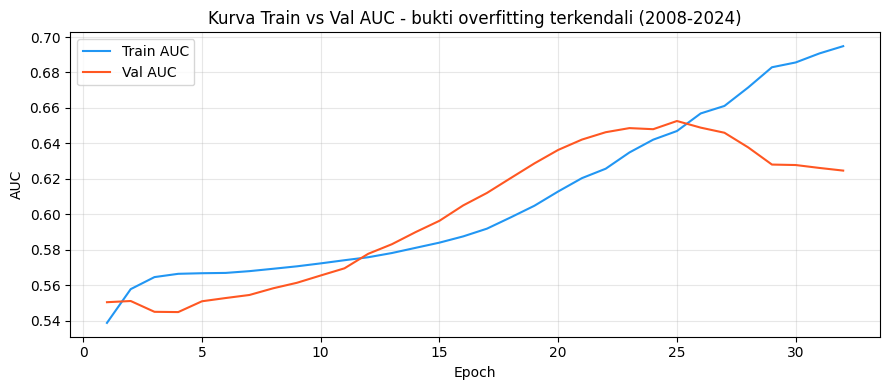

Plot disimpan ke: ../data/artifacts\lstm_train_val_auc_v6_2008_2024.png


In [15]:
# 4.3 — Kurva Train vs Val AUC - bukti overfitting terkendali

X_all_kv, y_all_kv, _ = build_sequences(df, best_window, FEATURE_COLS)
N_kv  = len(X_all_kv)
te_kv = int(N_kv * 0.70)
ve_kv = int(N_kv * 0.85)

Xtr_kv, ytr_kv = X_all_kv[:te_kv],      y_all_kv[:te_kv]
Xvl_kv, yvl_kv = X_all_kv[te_kv:ve_kv], y_all_kv[te_kv:ve_kv]
Xte_kv, _      = X_all_kv[ve_kv:],      y_all_kv[ve_kv:]
Xtr_kv, Xvl_kv, _, _ = scale_sequences(Xtr_kv, Xvl_kv, Xte_kv)

_model_kv, hist_kv, _best_auc_kv = train_one(
    Xtr_kv, ytr_kv, Xvl_kv, yvl_kv,
    params=best_params,
    seed=0,
    n_epochs=50,
    patience=7,
    lr=best_lr,
)
print(f'Best val AUC (seed 0): {_best_auc_kv:.4f}')

fig, ax = plt.subplots(figsize=(9, 4))
epochs_range = range(1, len(hist_kv['train_auc']) + 1)
ax.plot(epochs_range, hist_kv['train_auc'], label='Train AUC', color='#2196F3', linewidth=1.5)
ax.plot(epochs_range, hist_kv['val_auc'],   label='Val AUC',   color='#FF5722', linewidth=1.5)
ax.set_xlabel('Epoch')
ax.set_ylabel('AUC')
ax.set_title('Kurva Train vs Val AUC - bukti overfitting terkendali (2008-2024)', fontsize=12)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()

ARTIFACT_DIR = '../data/artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)
kurva_path = os.path.join(ARTIFACT_DIR, 'lstm_train_val_auc_v6_2008_2024.png')
plt.savefig(kurva_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Plot disimpan ke: {kurva_path}')


## 5. Evaluasi pada Test Set

Evaluasi model terbaik (dipilih berdasarkan val AUC) pada test set yang **tidak pernah
dilihat** selama pencarian hyperparameter.

Pemeriksaan **AUC terbalik** (flipped AUC) ditambahkan sebagai sanity check: jika
`AUC_flipped >> AUC_normal`, berarti model belajar dengan polaritas terbalik.


In [16]:
# 5.1 — Evaluasi model terbaik pada test set (seed ensemble 5 model)

X_all_best, y_all_best, dates_all_best = build_sequences(df, best_window, FEATURE_COLS)
N_best  = len(X_all_best)
te_best = int(N_best * 0.70)
ve_best = int(N_best * 0.85)

Xtr_b, ytr_b = X_all_best[:te_best],      y_all_best[:te_best]
Xvl_b, yvl_b = X_all_best[te_best:ve_best], y_all_best[te_best:ve_best]
Xte_b, yte_b = X_all_best[ve_best:],       y_all_best[ve_best:]

Xtr_b, Xvl_b, Xte_b, _ = scale_sequences(Xtr_b, Xvl_b, Xte_b)

N_SEEDS = 5
models_ensemble = []
print(f'Melatih {N_SEEDS} model (seed ensemble) dengan params: {best_params}')
for s in range(N_SEEDS):
    m, _, bval = train_one(Xtr_b, ytr_b, Xvl_b, yvl_b,
                           params=best_params, seed=s, n_epochs=50, patience=7, lr=best_lr)
    models_ensemble.append(m)
    print(f'  Seed {s}: best val AUC = {bval:.4f}')

probs  = ensemble_predict(models_ensemble, Xte_b)
preds  = (probs >= 0.5).astype(int)
y_test_ens = yte_b

acc_final = accuracy_score(y_test_ens, preds)
auc_final = roc_auc_score(y_test_ens, probs)
prec, rec, f1, _ = precision_recall_fscore_support(y_test_ens, preds, average='binary', zero_division=0)

print(f'\n=== Metrik Test (Seed Ensemble {N_SEEDS} model) ===')
print(f'Akurasi   : {acc_final:.4f}')
print(f'AUC       : {auc_final:.4f}')
print(f'Precision : {prec:.4f}')
print(f'Recall    : {rec:.4f}')
print(f'F1        : {f1:.4f}')

auc_normal  = roc_auc_score(y_test_ens, probs)
auc_flipped = roc_auc_score(y_test_ens, 1.0 - probs)
print(f'\nSanity check polaritas:')
print(f'  AUC normal  : {auc_normal:.4f}')
print(f'  AUC flipped : {auc_flipped:.4f}')
if auc_flipped > auc_normal + 0.05:
    print('  PERINGATAN: model mungkin belajar dengan polaritas terbalik!')
else:
    print('  OK: polaritas prediksi sudah benar (atau mendekati acak).')

np.random.seed(42)
rand_probs = np.random.uniform(0, 1, size=len(y_test_ens))
rand_preds = (rand_probs >= 0.5).astype(int)
rand_auc   = roc_auc_score(y_test_ens, rand_probs)
rand_acc   = accuracy_score(y_test_ens, rand_preds)

always_up_acc = float(np.mean(y_test_ens == 1))
always_up_auc = 0.5

baseline_df = pd.DataFrame([
    {'Model': f'LSTM seed-ensemble ({N_SEEDS} seed)', 'AUC': round(auc_final, 4), 'Accuracy': round(acc_final, 4)},
    {'Model': 'Always-Up (baseline naif)',             'AUC': always_up_auc,      'Accuracy': round(always_up_acc, 4)},
    {'Model': 'Random (prob ~ U(0,1), seed=42)',       'AUC': round(rand_auc, 4), 'Accuracy': round(rand_acc, 4)},
])
print('\n=== Tabel Perbandingan Baseline ===')
print(baseline_df.to_string(index=False))
print('\nCatatan: walk-forward (Bagian 6) adalah hakim utama karena mengevaluasi AUC pada')
print('banyak jendela waktu OOS, bukan hanya satu test slice.')

# Kalibrasi Platt + Threshold Tuned (anti-leakage dari val)
p_val_eval   = ensemble_predict(models_ensemble, Xvl_b)
probs_cal    = calibrate_platt(p_val_eval, yvl_b, probs)
p_val_cal    = calibrate_platt(p_val_eval, yvl_b, p_val_eval)
thr_eval     = tune_threshold(yvl_b, p_val_cal, 'youden')

m_cal = full_metrics(y_test_ens, probs_cal, thr=thr_eval)
acc_cal  = m_cal['accuracy']
prec_cal = m_cal['precision']
rec_cal  = m_cal['recall']
f1_cal   = m_cal['f1']

print(f'\n=== Metrik Test (kalibrasi Platt + threshold tuned @ {thr_eval:.2f}) ===')
print(f'AUC       : {m_cal["auc"]:.4f}  (identik - kalibrasi Platt monotonik)')
print(f'Accuracy  : {acc_cal:.4f}')
print(f'Precision : {prec_cal:.4f}')
print(f'Recall    : {rec_cal:.4f}')
print(f'F1        : {f1_cal:.4f}')


Melatih 5 model (seed ensemble) dengan params: {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5}
  Seed 0: best val AUC = 0.6526
  Seed 1: best val AUC = 0.6636
  Seed 2: best val AUC = 0.6387
  Seed 3: best val AUC = 0.6504
  Seed 4: best val AUC = 0.6445

=== Metrik Test (Seed Ensemble 5 model) ===
Akurasi   : 0.5382
AUC       : 0.4966
Precision : 0.5720
Recall    : 0.7673
F1        : 0.6554

Sanity check polaritas:
  AUC normal  : 0.4966
  AUC flipped : 0.5034
  OK: polaritas prediksi sudah benar (atau mendekati acak).

=== Tabel Perbandingan Baseline ===
                          Model    AUC  Accuracy
    LSTM seed-ensemble (5 seed) 0.4966    0.5382
      Always-Up (baseline naif) 0.5000    0.5722
Random (prob ~ U(0,1), seed=42) 0.5191    0.5241

Catatan: walk-forward (Bagian 6) adalah hakim utama karena mengevaluasi AUC pada
banyak jendela waktu OOS, bukan hanya satu test slice.

=== Metrik Test (kalibrasi Platt + threshold tuned @ 0.68) ===
AUC       : 0.4966  (identik - kali

Akurasi   : 0.5382
AUC       : 0.4966
Precision : 0.5720
Recall    : 0.7673
F1        : 0.6554

PERINGATAN: Model terlihat degenerasi (selalu memprediksi satu kelas).
  Recall=1.0 atau precision ~ base-rate menunjukkan masalah ini.
  Gunakan AUC sebagai metrik yang lebih andal dalam kasus ini.


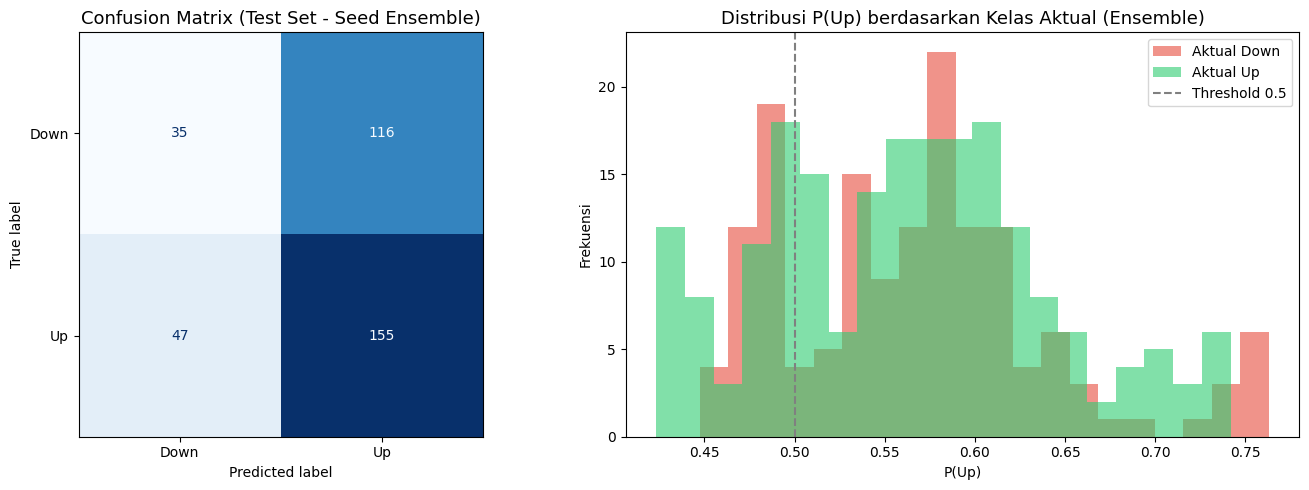

Plot disimpan ke: ../data/artifacts\lstm_confusion_dist_v6_2008_2024.png


In [17]:
# 5.2 — Confusion matrix dan distribusi P(Up) (ensemble)

ARTIFACT_DIR = '../data/artifacts'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

labels_cm = y_test_ens
preds_cm  = preds
probs_cm  = probs

print(f'Akurasi   : {acc_final:.4f}')
print(f'AUC       : {auc_final:.4f}')
print(f'Precision : {prec:.4f}')
print(f'Recall    : {rec:.4f}')
print(f'F1        : {f1:.4f}')

base_rate = labels_cm.mean()
if rec >= 1.0 or abs(prec - base_rate) < 0.05:
    print()
    print('PERINGATAN: Model terlihat degenerasi (selalu memprediksi satu kelas).')
    print('  Recall=1.0 atau precision ~ base-rate menunjukkan masalah ini.')
    print('  Gunakan AUC sebagai metrik yang lebih andal dalam kasus ini.')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cm_arr = confusion_matrix(labels_cm, preds_cm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_arr, display_labels=['Down', 'Up'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix (Test Set - Seed Ensemble)', fontsize=13)

for cls, lbl, color in [(0, 'Aktual Down', '#e74c3c'), (1, 'Aktual Up', '#2ecc71')]:
    mask = labels_cm == cls
    axes[1].hist(probs_cm[mask], bins=20, alpha=0.6, label=lbl, color=color)
axes[1].axvline(0.5, linestyle='--', color='gray', label='Threshold 0.5')
axes[1].set_xlabel('P(Up)')
axes[1].set_ylabel('Frekuensi')
axes[1].set_title('Distribusi P(Up) berdasarkan Kelas Aktual (Ensemble)', fontsize=13)
axes[1].legend()

plt.tight_layout()
save_path = os.path.join(ARTIFACT_DIR, 'lstm_confusion_dist_v6_2008_2024.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Plot disimpan ke: {save_path}')


## 6. Walk-Forward Validation (Estimasi AUC Robust)

Satu test slice (Bagian 5) relatif kecil & noisy untuk menyimpulkan ada/tidaknya sinyal
secara meyakinkan. Walk-forward me-**retrain model di banyak jendela waktu** lalu
rata-ratakan metrik.

**Rolling window** (bukan expanding): train region hanya `WF_TRAIN_SIZE` sampel terbaru -
adaptif ke rezim pasar terkini (concept drift). Kalibrasi Platt (fit val) + threshold
Youden's J (anti-leakage: fit/tuned hanya di train/val fold, test fold tidak pernah
disentuh sebelum evaluasi final).

**Perbedaan dari notebook 03:** `n_folds` dinaikkan dari 5 -> **8** - data 2008-2024 cukup
panjang untuk fold lebih granular, sehingga walk-forward benar-benar menguji temuan
"regime-dependent sign-flip" lintas lebih banyak rezim pasar (GFC 2008, bull market
2010-an, COVID crash 2020, recovery/rate-hike 2021-2023).

> Interpretasi: mean AUC ~0.50 = tidak ada edge OOS konsisten (EMH). >0.55 stabil = ada
> edge yang bertahan.


In [18]:
# 6.1 — Walk-Forward Validation: fungsi reusable + konfigurasi dari grid search
# (fungsi run_walk_forward SAMA PERSIS notebook 03 - generic, reusable)

from sklearn.metrics import roc_auc_score

def run_walk_forward(wf_train_size, config, lr, window, n_seeds=5, n_folds=5, verbose=True):
    """Walk-forward rolling. wf_train_size=None => expanding (tr_lo=0).
    Per fold: scaling train-only, seed ensemble, kalibrasi Platt + threshold Youden's J
    (semua fit/tune HANYA di train/val fold -> anti-leakage)."""
    X_wf, y_wf, dates_wf = build_sequences(df, window, FEATURE_COLS)
    N_wf = len(X_wf)
    start_idx  = int(N_wf * 0.50)
    test_block = (N_wf - start_idx) // n_folds
    rows, all_lab, all_prb = [], [], []
    for k in range(n_folds):
        te_start = start_idx + k * test_block
        te_end   = te_start + test_block if k < n_folds - 1 else N_wf
        tr_lo    = 0 if wf_train_size is None else max(0, te_start - wf_train_size)
        reg_len  = te_start - tr_lo
        val_sz   = max(1, int(reg_len * 0.15))
        Xtr, ytr = X_wf[tr_lo:te_start - val_sz], y_wf[tr_lo:te_start - val_sz]
        Xvl, yvl = X_wf[te_start - val_sz:te_start], y_wf[te_start - val_sz:te_start]
        Xte, yte = X_wf[te_start:te_end], y_wf[te_start:te_end]
        Xtr, Xvl, Xte, _ = scale_sequences(Xtr, Xvl, Xte)
        models = [train_one(Xtr, ytr, Xvl, yvl, params=config, seed=s,
                            n_epochs=40, patience=7, lr=lr)[0] for s in range(n_seeds)]
        p_val  = ensemble_predict(models, Xvl)
        p_test = ensemble_predict(models, Xte)
        p_test_cal = calibrate_platt(p_val, yvl, p_test)
        p_val_cal  = calibrate_platt(p_val, yvl, p_val)
        thr = tune_threshold(yvl, p_val_cal, metric='youden')
        m = full_metrics(yte, p_test_cal, thr=thr)
        m.update({'fold': k + 1, 'threshold': round(thr, 3),
                  'n_train': len(ytr), 'n_test': len(yte)})
        rows.append(m)
        all_lab.extend(yte.tolist()); all_prb.extend(np.asarray(p_test_cal).tolist())
        if verbose:
            print(f"Fold {k+1}/{n_folds} | train={len(ytr):4d} test={len(yte):3d}"
                  f" [{pd.Timestamp(dates_wf[te_start]).date()}-{pd.Timestamp(dates_wf[te_end-1]).date()}]"
                  f" thr={thr:.2f} | AUC={m['auc']:.4f} Acc={m['accuracy']:.4f}"
                  f" P={m['precision']:.4f} R={m['recall']:.4f} F1={m['f1']:.4f}")
    wdf = pd.DataFrame(rows)[['fold','n_train','n_test','threshold','auc','accuracy','precision','recall','f1']]
    pooled = roc_auc_score(all_lab, all_prb)
    return wdf, pooled


# --- Konfigurasi WF: KONSISTEN dengan grid search (best_params + best_lr) ---
WF_WINDOW     = best_window
WF_FOLDS      = 8   # dinaikkan dari 5 (notebook 03) -> 8, data 2008-2024 lebih panjang
WF_N_SEEDS    = 5
WF_CONFIG     = dict(best_params)
WF_LR         = best_lr
WF_TRAIN_SIZE = 400  # rolling window (dianalisis sensitivitasnya di Bagian 6b)

print(f'WF config (dari grid): {WF_CONFIG} | lr={WF_LR} | window={WF_WINDOW} | train_size={WF_TRAIN_SIZE} | folds={WF_FOLDS}')
wf_df, pooled_auc_wf = run_walk_forward(WF_TRAIN_SIZE, WF_CONFIG, WF_LR, WF_WINDOW,
                                        n_seeds=WF_N_SEEDS, n_folds=WF_FOLDS, verbose=True)
wf_mean_auc = float(np.nanmean(wf_df['auc']))
wf_std_auc  = float(np.nanstd(wf_df['auc']))

print('\n' + '=' * 70)
print('Metrik per fold (rolling window, kalibrasi Platt, threshold tuned Youden-J di val):')
print(wf_df.round(4).to_string(index=False))
print('-' * 70)
print('Rata-rata lintas fold:')
for col in ['auc','accuracy','precision','recall','f1']:
    print(f'  {col:9s}: {wf_df[col].mean():.4f} +/- {wf_df[col].std():.4f}')
print(f'Pooled AUC (prob terkalibrasi): {pooled_auc_wf:.4f}')
print('=' * 70)
if wf_mean_auc < 0.53:
    print('VERDICT: AUC ~0.50 -> tidak ada edge OOS konsisten (sesuai EMH).')
elif wf_mean_auc < 0.55:
    print('VERDICT: edge sangat tipis & belum meyakinkan.')
else:
    print('VERDICT: ada edge yang bertahan lintas waktu - layak dilanjutkan.')


WF config (dari grid): {'hidden_size': 32, 'num_layers': 1, 'dropout': 0.5} | lr=0.0005 | window=30 | train_size=400 | folds=8
Fold 1/8 | train= 340 test=146 [2015-11-25-2017-03-16] thr=0.55 | AUC=0.6360 Acc=0.5342 P=0.8108 R=0.3297 F1=0.4688
Fold 2/8 | train= 340 test=146 [2017-03-17-2018-08-29] thr=0.30 | AUC=0.4436 Acc=0.6986 P=0.6986 R=1.0000 F1=0.8226
Fold 3/8 | train= 340 test=146 [2018-08-30-2019-08-08] thr=0.65 | AUC=0.5166 Acc=0.5753 P=0.6042 R=0.7073 F1=0.6517
Fold 4/8 | train= 340 test=146 [2019-08-09-2020-06-18] thr=0.60 | AUC=0.6474 Acc=0.6301 P=0.7349 R=0.6559 F1=0.6932
Fold 5/8 | train= 340 test=146 [2020-06-19-2021-04-30] thr=0.67 | AUC=0.6943 Acc=0.2534 P=0.0000 R=0.0000 F1=0.0000
Fold 6/8 | train= 340 test=146 [2021-05-05-2022-04-21] thr=0.30 | AUC=0.3593 Acc=0.5479 P=0.5479 R=1.0000 F1=0.7080
Fold 7/8 | train= 340 test=146 [2022-04-22-2023-02-03] thr=0.35 | AUC=0.6580 Acc=0.6301 P=0.6866 R=0.5823 F1=0.6301
Fold 8/8 | train= 340 test=152 [2023-02-13-2024-02-26] thr=0.

## 6b. Analisis Sensitivitas `WF_TRAIN_SIZE`

Walk-forward dengan `WF_TRAIN_SIZE=400` adalah pilihan tunggal yang perlu divalidasi. Cell
berikut melakukan **sweep** atas berbagai ukuran train - termasuk mode *expanding*
(`wf_train_size=None`) - untuk menguji apakah hasil mean AUC stabil atau bergantung pada
pilihan satu nilai saja.

**Perbedaan dari notebook 03:** kandidat sweep diperluas ke **[200, 300, 400, 500, 750,
1000, expanding]** (sebelumnya hanya sampai 500) - data 2008-2024 yang jauh lebih panjang
memungkinkan window train yang lebih besar untuk diuji juga.

Semua hasil dilaporkan lengkap - tidak ada cherry-picking.

> **Catatan:** setiap entri sweep = `n_folds x n_seeds` siklus pelatihan - berat secara
> komputasi (lebih berat dari notebook 03 karena `n_folds=8` dan kandidat sweep lebih
> banyak).


train_size=      200 | mean_auc=0.4882 +/- 0.1050 | pooled=0.4997
train_size=      300 | mean_auc=0.5206 +/- 0.1196 | pooled=0.5350
train_size=      400 | mean_auc=0.5382 +/- 0.1398 | pooled=0.5257
train_size=      500 | mean_auc=0.4801 +/- 0.1269 | pooled=0.4961
train_size=      750 | mean_auc=0.5529 +/- 0.1112 | pooled=0.5039
train_size=     1000 | mean_auc=0.5200 +/- 0.1260 | pooled=0.4859
train_size=     None | mean_auc=0.5623 +/- 0.1051 | pooled=0.4612

=== Sensitivitas WF_TRAIN_SIZE ===
train_size  mean_auc  std_auc  mean_acc  mean_f1  pooled_auc
       200    0.4882   0.1050    0.5376   0.5955      0.4997
       300    0.5206   0.1196    0.6327   0.7673      0.5350
       400    0.5382   0.1398    0.5676   0.5972      0.5257
       500    0.4801   0.1269    0.5504   0.6102      0.4961
       750    0.5529   0.1112    0.5659   0.6453      0.5039
      1000    0.5200   0.1260    0.4598   0.3703      0.4859
 expanding    0.5623   0.1051    0.6181   0.7445      0.4612


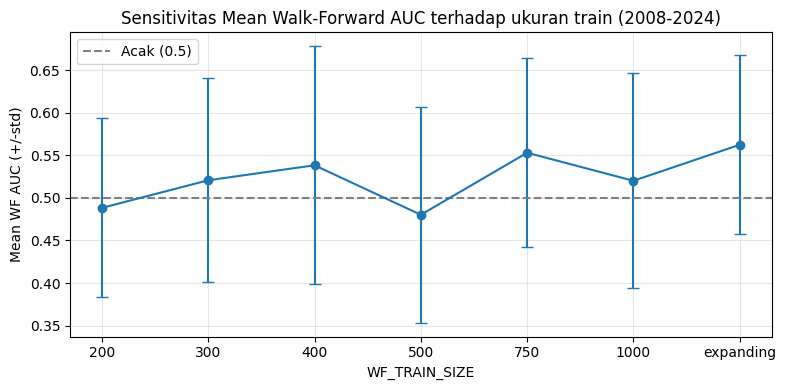

Plot disimpan ke: ../data/artifacts\lstm_wf_trainsize_sensitivity_v6_2008_2024.png


In [19]:
# 6b.1 — Analisis sensitivitas WF_TRAIN_SIZE: sweep + laporkan SEMUA hasil (anti cherry-pick)
WF_SWEEP = [200, 300, 400, 500, 750, 1000, None]
sens_rows = []
for wts in WF_SWEEP:
    wdf_s, pooled_s = run_walk_forward(wts, WF_CONFIG, WF_LR, WF_WINDOW,
                                       n_seeds=WF_N_SEEDS, n_folds=WF_FOLDS, verbose=False)
    sens_rows.append({
        'train_size': 'expanding' if wts is None else wts,
        'mean_auc':   round(float(wdf_s['auc'].mean()), 4),
        'std_auc':    round(float(wdf_s['auc'].std()), 4),
        'mean_acc':   round(float(wdf_s['accuracy'].mean()), 4),
        'mean_f1':    round(float(wdf_s['f1'].mean()), 4),
        'pooled_auc': round(float(pooled_s), 4),
    })
    print(f"train_size={str(wts):>9} | mean_auc={sens_rows[-1]['mean_auc']:.4f} "
          f"+/- {sens_rows[-1]['std_auc']:.4f} | pooled={sens_rows[-1]['pooled_auc']:.4f}")

wf_sens_df = pd.DataFrame(sens_rows)
print('\n=== Sensitivitas WF_TRAIN_SIZE ===')
print(wf_sens_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
xlabels = wf_sens_df['train_size'].astype(str).tolist()
ax.errorbar(range(len(wf_sens_df)), wf_sens_df['mean_auc'], yerr=wf_sens_df['std_auc'],
            marker='o', capsize=4, linewidth=1.5)
ax.axhline(0.5, linestyle='--', color='gray', label='Acak (0.5)')
ax.set_xticks(range(len(wf_sens_df))); ax.set_xticklabels(xlabels)
ax.set_xlabel('WF_TRAIN_SIZE'); ax.set_ylabel('Mean WF AUC (+/-std)')
ax.set_title('Sensitivitas Mean Walk-Forward AUC terhadap ukuran train (2008-2024)')
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
sens_path = os.path.join('../data/artifacts', 'lstm_wf_trainsize_sensitivity_v6_2008_2024.png')
plt.savefig(sens_path, dpi=120, bbox_inches='tight'); plt.show()
print(f'Plot disimpan ke: {sens_path}')


## 6c. Baseline Tambahan: Model Tunggal ala Notebook 05 (opsional)

Notebook 05 (`05_LSTM_Expertiment_withScaler.ipynb`) memakai pendekatan lebih sederhana:
**satu model** (bukan ensemble 5-seed), tanpa walk-forward. Sel berikut melatih **satu
model tunggal** (seed=0, `best_params`/`best_lr` hasil grid search yang sama) pada split
test-set yang sama seperti Bagian 5, untuk membandingkan: apakah kompleksitas ensemble
5-seed benar-benar memberi nilai tambah di horizon data yang lebih panjang ini, atau
performanya setara model tunggal?

Catatan: perbandingan ini HANYA pada satu test-set slice (sama seperti Bagian 5) - bukan
walk-forward. Untuk kesimpulan robust soal ensemble vs single-model, walk-forward (Bagian
6-6b) tetap jadi hakim utama.


In [20]:
# 6c.1 — Baseline model tunggal (non-ensemble), mirip pendekatan notebook 05
# Reuse split & scaling yang SAMA dari Bagian 5 (Xtr_b, Xvl_b, Xte_b, yte_b, best_params, best_lr)

single_model, _single_hist, _single_best_val_auc = train_one(
    Xtr_b, ytr_b, Xvl_b, yvl_b,
    params=best_params, seed=0, n_epochs=50, patience=7, lr=best_lr,
)

single_probs = ensemble_predict([single_model], Xte_b)  # 1 model saja -> setara predict biasa
single_preds = (single_probs >= 0.5).astype(int)

single_auc = roc_auc_score(yte_b, single_probs)
single_acc = accuracy_score(yte_b, single_preds)
single_prec, single_rec, single_f1, _ = precision_recall_fscore_support(
    yte_b, single_preds, average='binary', zero_division=0
)

print('=== Model Tunggal (seed=0, ala Notebook 05) vs Ensemble 5-seed (Bagian 5) ===')
comparison_df = pd.DataFrame([
    {'Model': 'LSTM tunggal (seed=0, ala notebook 05)', 'AUC': round(single_auc, 4), 'Accuracy': round(single_acc, 4), 'Precision': round(single_prec, 4), 'Recall': round(single_rec, 4), 'F1': round(single_f1, 4)},
    {'Model': f'LSTM seed-ensemble ({N_SEEDS} seed, notebook 06 utama)', 'AUC': round(auc_final, 4), 'Accuracy': round(acc_final, 4), 'Precision': round(prec, 4), 'Recall': round(rec, 4), 'F1': round(f1, 4)},
])
print(comparison_df.to_string(index=False))
print()
print('Catatan: perbandingan ini HANYA pada satu test-set slice (sama seperti Bagian 5) -')
print('bukan walk-forward. Untuk kesimpulan robust, walk-forward (Bagian 6-6b) tetap hakim utama.')


=== Model Tunggal (seed=0, ala Notebook 05) vs Ensemble 5-seed (Bagian 5) ===
                                         Model    AUC  Accuracy  Precision  Recall     F1
        LSTM tunggal (seed=0, ala notebook 05) 0.4842    0.5524     0.5748  0.8366 0.6815
LSTM seed-ensemble (5 seed, notebook 06 utama) 0.4966    0.5382     0.5720  0.7673 0.6554

Catatan: perbandingan ini HANYA pada satu test-set slice (sama seperti Bagian 5) -
bukan walk-forward. Untuk kesimpulan robust, walk-forward (Bagian 6-6b) tetap hakim utama.


## 7. Simpan Artefak Model

Artefak disimpan dengan nama **terisolasi** (`*_v6_2008_2024.*`) - TIDAK menimpa artefak
notebook 03 (`*_v5.*`) maupun model produksi.


In [21]:
# 7.1 — Simpan artefak model v6 (horizon 2008-2024)

import joblib

WEIGHTS_DIR = '../data/artifacts/lstm_weights'
os.makedirs(WEIGHTS_DIR, exist_ok=True)

# 1. Simpan ensemble (list 5 state_dict)
ensemble_path = os.path.join(WEIGHTS_DIR, 'direction_classifier_v6_2008_2024.pt')
torch.save([m.state_dict() for m in models_ensemble], ensemble_path)
print(f'Ensemble model disimpan ke : {ensemble_path}')

# 2. Simpan scaler (difit pada X_train split final di Bagian 5)
X_all_sv, y_all_sv, _ = build_sequences(df, best_window, FEATURE_COLS)
N_sv  = len(X_all_sv)
te_sv = int(N_sv * 0.70)
ve_sv = int(N_sv * 0.85)
_, _, _, save_scaler = scale_sequences(
    X_all_sv[:te_sv], X_all_sv[te_sv:ve_sv], X_all_sv[ve_sv:]
)
scaler_path = os.path.join(WEIGHTS_DIR, 'scaler_v6_2008_2024.joblib')
joblib.dump(save_scaler, scaler_path)
print(f'Scaler disimpan ke         : {scaler_path}')

# 3. Simpan metadata
metadata_v6 = {
    'version'     : 'v6_2008_2024',
    'horizon_range': '2008-01-02 to 2024-03-04',
    'feature_cols': FEATURE_COLS,
    'input_size'  : len(FEATURE_COLS),
    'best_params' : best_params,
    'window'      : best_window,
    'horizon'     : HORIZON,
    'threshold'   : THRESHOLD,
    'n_seeds'     : 5,
    'metrics_test': {
        'auc'             : round(auc_final, 4),
        'accuracy'        : round(acc_final, 4),
        'precision'       : round(prec, 4),
        'recall'          : round(rec, 4),
        'f1'              : round(f1, 4),
        'threshold_tuned' : round(thr_eval, 3),
        'accuracy_tuned'  : round(acc_cal, 4),
        'precision_tuned' : round(prec_cal, 4),
        'recall_tuned'    : round(rec_cal, 4),
        'f1_tuned'        : round(f1_cal, 4),
    },
    'walk_forward': {
        'method'    : 'rolling-window',
        'train_size': WF_TRAIN_SIZE,
        'folds'     : WF_FOLDS,
        'mean_auc'  : round(wf_mean_auc, 4),
        'std_auc'   : round(wf_std_auc, 4),
        'mean_accuracy' : round(float(wf_df['accuracy'].mean()), 4),
        'mean_precision': round(float(wf_df['precision'].mean()), 4),
        'mean_recall'   : round(float(wf_df['recall'].mean()), 4),
        'mean_f1'       : round(float(wf_df['f1'].mean()), 4),
        'fold_metrics'  : wf_df.round(4).to_dict('records'),
        **({'train_size_sensitivity': wf_sens_df.to_dict('records')} if 'wf_sens_df' in dir() else {}),
    },
    'single_model_baseline': (
        {
            'auc': round(single_auc, 4),
            'accuracy': round(single_acc, 4),
            'precision': round(single_prec, 4),
            'recall': round(single_rec, 4),
            'f1': round(single_f1, 4),
        } if 'single_auc' in dir() else None
    ),
    'notes': [
        'Notebook 06: replikasi PERSIS metodologi notebook 03 (v5) pada horizon data yang '
        'jauh lebih panjang (2008-2024, ~16 tahun) dibanding notebook 03 (2018-2024, ~6 tahun) '
        '- mencakup Krisis Finansial Global 2008 dan Crash COVID-19 2020.',
        '10 fitur SAMA PERSIS notebook 03 (tidak menambah indikator baru): 8 indikator '
        'teknikal stasioner (RSI, MACD hist, BB bandwidth, volatility_20, close_vs_ema20, '
        'bb_pct_b, ret_close, ret_volume) + 2 sentimen (sentiment_mean shifted(1), '
        'sentiment_mean_ma3 shifted(1)).',
        'Arsitektur LSTMClassifier SAMA PERSIS notebook 03 (hidden=32 default / 1 layer, '
        'dropout=0.5 di FC, mean-pooling, Adam weight_decay=1e-4, class weight '
        'inverse-frequency, seed ensemble 5 model, StandardScaler fit train-only).',
        'Grid search DIJALANKAN ULANG dari nol pada dataset 2008-2024 (bukan reuse '
        'hyperparameter dari notebook 03) karena distribusi data jauh berbeda.',
        'Walk-forward rolling-window: n_folds dinaikkan 5->8 dibanding notebook 03 (data '
        'lebih panjang -> fold lebih granular, menguji regime sign-flip lebih detail). '
        'WF_TRAIN_SIZE=400 divalidasi via sweep [200,300,400,500,750,1000,expanding] '
        '(kandidat diperluas dibanding notebook 03 yang hanya sampai 500).',
        'Baseline tambahan: model tunggal (non-ensemble, ala notebook 05) dibandingkan '
        'terhadap ensemble 5-seed pada satu test-set slice (lihat single_model_baseline).',
        'PRINSIP YANG DITEGAKKAN (sama seperti notebook 03 dan seluruh sesi sebelumnya): '
        'hasil dilaporkan APA ADANYA, termasuk bila sinyal tetap lemah/dekat EMH di '
        'horizon yang lebih panjang ini - TIDAK di-tuning demi angka yang terlihat bagus '
        '(anti p-hacking). Pooled AUC adalah angka konservatif utama, bukan mean per-fold.',
        'CATATAN EKSEKUSI: notebook ini ditulis LENGKAP tapi BELUM dieksekusi (sesuai '
        'instruksi eksplisit user) - seluruh cell outputs=[] / execution_count=null. '
        'Eksekusi adalah langkah terpisah berikutnya, disarankan via script headless '
        '(nbconvert/papermill) bukan cell-by-cell interaktif, mengingat total training run '
        'yang berat (grid search + walk-forward + sensitivity sweep, data 2.6x lebih '
        'banyak dari notebook 03).',
    ],
}

meta_path = os.path.join(WEIGHTS_DIR, 'metadata_v6_2008_2024.json')
with open(meta_path, 'w', encoding='utf-8') as f:
    json.dump(metadata_v6, f, indent=2, ensure_ascii=False)
print(f'Metadata disimpan ke       : {meta_path}')

print()
print('File artefak tersimpan:')
for fname in sorted(os.listdir(WEIGHTS_DIR)):
    if '2008_2024' in fname:
        fpath = os.path.join(WEIGHTS_DIR, fname)
        size_kb = os.path.getsize(fpath) / 1024
        print(f'  {fname}  ({size_kb:.1f} KB)')


Ensemble model disimpan ke : ../data/artifacts/lstm_weights\direction_classifier_v6_2008_2024.pt
Scaler disimpan ke         : ../data/artifacts/lstm_weights\scaler_v6_2008_2024.joblib
Metadata disimpan ke       : ../data/artifacts/lstm_weights\metadata_v6_2008_2024.json

File artefak tersimpan:
  direction_classifier_v6_2008_2024.pt  (118.5 KB)
  metadata_v6_2008_2024.json  (6.5 KB)
  scaler_v6_2008_2024.joblib  (0.8 KB)


## 8. Backtest: Distribusi Prediksi vs Aktual (Cek "Selalu Menebak Up")

Sel berikut membuat tabel backtest harian pada test-set (prediksi ensemble 5-seed vs
aktual, plus model tunggal dari Bagian 6c), lalu menghitung proporsi prediksi Up/Down
dibanding proporsi aktual Up/Down, dan confusion matrix per kelas. Tujuannya memverifikasi
langsung apakah model betul-betul selalu menebak "Up" (class collapse) seperti temuan pada
varian OHLCV-only/notebook 05 sebelumnya, atau memang bervariasi antara Up/Down.

In [ ]:
# 8.1 - Backtest: cek apakah model selalu menebak 'Up' (class collapse)
dates_test_b = dates_all_best[ve_best:]

backtest_df = pd.DataFrame({
    'date': pd.to_datetime(dates_test_b),
    'actual': y_test_ens.astype(int),
    'pred_ensemble': preds.astype(int),
    'pred_single': single_preds.astype(int),
    'prob_ensemble': probs,
    'prob_single': single_probs,
})
backtest_df['correct_ensemble'] = (backtest_df['actual'] == backtest_df['pred_ensemble'])
backtest_df['correct_single']   = (backtest_df['actual'] == backtest_df['pred_single'])

print('=== Backtest harian (10 baris pertama) ===')
print(backtest_df.head(10).to_string(index=False))

print()
print(f"=== Distribusi Prediksi vs Aktual (test-set, n={len(backtest_df)}) ===")
dist_df = pd.DataFrame({
    'Aktual Up (%)':           [backtest_df['actual'].mean() * 100],
    'Pred. Up - Ensemble (%)': [backtest_df['pred_ensemble'].mean() * 100],
    'Pred. Up - Single (%)':   [backtest_df['pred_single'].mean() * 100],
})
print(dist_df.round(2).to_string(index=False))

def cek_class_collapse(nama, actual, pred):
    tp = int(((pred == 1) & (actual == 1)).sum())
    tn = int(((pred == 0) & (actual == 0)).sum())
    fp = int(((pred == 1) & (actual == 0)).sum())
    fn = int(((pred == 0) & (actual == 1)).sum())
    recall_up   = tp / (tp + fn) if (tp + fn) > 0 else float('nan')
    recall_down = tn / (tn + fp) if (tn + fp) > 0 else float('nan')
    collapse = bool((pred == pred[0]).all())
    print()
    print(f'--- {nama} ---')
    print(f'Confusion: tp={tp}, tn={tn}, fp={fp}, fn={fn}')
    print(f'Recall Up   : {recall_up:.4f}')
    print(f'Recall Down : {recall_down:.4f}')
    if collapse:
        arah = 'UP' if pred[0] == 1 else 'DOWN'
        print(f'>>> CLASS COLLAPSE: model SELALU menebak {arah} sepanjang test-set!')
    elif recall_down == 0.0:
        print('>>> PERINGATAN: model tidak pernah menebak Down (recall_down=0) - mendekati class collapse.')
    else:
        print('>>> OK: model memprediksi kedua arah (Up & Down), bukan class collapse penuh.')
    return collapse

collapse_ens = cek_class_collapse('Ensemble 5-seed', backtest_df['actual'].values, backtest_df['pred_ensemble'].values)
collapse_single = cek_class_collapse('Model Tunggal (seed=0)', backtest_df['actual'].values, backtest_df['pred_single'].values)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(backtest_df['date'], backtest_df['actual'], label='Aktual (0=Down,1=Up)', drawstyle='steps-post', linewidth=1.5, alpha=0.7)
ax.plot(backtest_df['date'], backtest_df['pred_ensemble'], label='Prediksi Ensemble', drawstyle='steps-post', linewidth=1.2, linestyle='--')
ax.set_yticks([0, 1]); ax.set_yticklabels(['Down', 'Up'])
ax.set_title('Backtest: Prediksi Ensemble vs Aktual (Test-Set 2008-2024)')
ax.legend(loc='upper right'); ax.grid(alpha=0.3)
plt.tight_layout()
backtest_plot_path = os.path.join('../data/artifacts', 'lstm_backtest_v6_2008_2024.png')
plt.savefig(backtest_plot_path, dpi=120, bbox_inches='tight'); plt.show()
print()
print(f'Plot backtest disimpan ke: {backtest_plot_path}')